# First-arrival tomography: held-out straight-ray inversion

**Level 2 — Applied inverse methods** · 60–75 min · linear algebra and least squares

## Objectives
Build a ray-length matrix for synthetic crosshole arrivals; solve a regularized 2D slowness inverse on training sources; compare a homogeneous baseline and the inverse on whole held-out source depths; inspect coverage and non-uniqueness.

## Setup

Run from repository root in the pinned notebook environment:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

The experiment cell prints active package versions.

## Data
All arrivals are generated deterministically in memory. This is synthetic crosshole data, not the Koenigsee survey. The product's data-pipeline/traveltime.py has a separate strict .sgt parser/QC and conditional pyGIMLi inversion; source survey bytes are not bundled, so this chapter does not fabricate or substitute field observations.

## Method

For fixed path Γᵢ, first-arrival time is tᵢ=∫Γᵢ s(x,z)dl, with slowness s=1/v in s/m. Cell discretization gives t≈A s; Aᵢⱼ is the length in metres of ray i through cell j. The problem is linear in slowness only while straight-ray geometry is fixed. It omits bending, refraction topology, anisotropy and finite-frequency effects.

Estimate training-only homogeneous slowness s₀, then solve dimensionless q=(s−s₀)/(1/3000 s/m) by minimizing ||W(A s₀ + A s_scale q − t)||² + λ||Dq||². W=1/σt; D is a neighbour first-difference operator. Entire source depths are held out; held times do not define s₀, inversion, λ or model choice. Held-out RMSE/WRMS are diagnostics after fitting.

Product M09 in data-pipeline/traveltime.py validates attributed .sgt geometry/picks, retains anomaly flags, creates whole-shot splits and runs a nonlinear pyGIMLi inverse on a frozen mesh. Its field data are absent here. This notebook is an executable synthetic linear companion, not a replay or proxy for that field workflow.

### Questions
1. Where are ray angles or counts weak, and which cells are least identifiable?
2. Does the inverse improve held-out error over the homogeneous baseline?
3. What changes when rays are bent and the matrix is rebuilt iteratively?

### Experiment 2 — edit noise and smoothness, then fit

Change RAY_NOISE_S and LAMBDA_SMOOTH. A fixed seed reproduces the added pick noise. Hold out complete source depths rather than random ray rows.

In [1]:
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'scipy', 'matplotlib']})
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, vstack
from scipy.sparse.linalg import lsqr

# Synthetic crosshole survey: vertical borehole strings; coordinates in metres.
nx, nz = 12, 6
dx = dz = 500.0
x_edges = np.arange(nx+1)*dx
z_edges = np.arange(nz+1)*dz
x_src = np.zeros(12); z_src = (np.arange(12)+0.5)*250.0
x_rec = np.full(12, nx*dx); z_rec = (np.arange(12)+0.5)*250.0
# Known synthetic truth; never passed to the inverse.
velocity_true = np.full((nz,nx), 2600.0)
velocity_true[2:,:] = 3600.0
velocity_true[1:5,5:8] = 2050.0
slowness_true = 1.0/velocity_true
src_ids, rec_ids = np.meshgrid(np.arange(12),np.arange(12),indexing='ij')
src_ids, rec_ids = src_ids.ravel(), rec_ids.ravel()
n_rays = len(src_ids)
rows, cols, lengths = [], [], []
for i,(si,ri) in enumerate(zip(src_ids,rec_ids)):
    x0,z0,x1,z1 = x_src[si],z_src[si],x_rec[ri],z_rec[ri]
    distance = np.hypot(x1-x0,z1-z0)
    n_sample = 5000
    u = (np.arange(n_sample)+.5)/n_sample
    xs = x0+u*(x1-x0); zs = z0+u*(z1-z0)
    ix = np.clip(np.searchsorted(x_edges,xs,side='right')-1,0,nx-1)
    iz = np.clip(np.searchsorted(z_edges,zs,side='right')-1,0,nz-1)
    cells, counts = np.unique(iz*nx+ix,return_counts=True)
    rows.extend([i]*len(cells)); cols.extend(cells.tolist())
    lengths.extend((counts*distance/n_sample).tolist())
A = csr_matrix((lengths,(rows,cols)),shape=(n_rays,nx*nz))
RAY_NOISE_S = 0.0005
SEED = 60427
sigma_t = RAY_NOISE_S
rng = np.random.default_rng(SEED)
t_obs = A@slowness_true.ravel()+rng.normal(0,sigma_t,n_rays)
# Entire source depths held out; source-index policy is fixed before looking at times.
held_sources = np.array([1,4,7,10])
held = np.isin(src_ids,held_sources); train = ~held
assert train.any() and held.any()
distance = np.asarray(A.sum(axis=1)).ravel()
s0 = float(np.dot(distance[train],t_obs[train])/np.dot(distance[train],distance[train]))
scale_s = 1/3000.0
Atr = A[train]
G = Atr*scale_s/sigma_t
rhs = (t_obs[train]-Atr@np.full(nx*nz,s0))/sigma_t
pairs=[]
for iz in range(nz):
    for ix in range(nx):
        j=iz*nx+ix
        if ix+1<nx: pairs.append((j,j+1))
        if iz+1<nz: pairs.append((j,j+nx))
rr=[]; cc=[]; vv=[]
for k,(a,b) in enumerate(pairs):
    rr.extend([k,k]); cc.extend([a,b]); vv.extend([-1.,1.])
D=csr_matrix((vv,(rr,cc)),shape=(len(pairs),nx*nz))
LAMBDA_SMOOTH=0.45
system=vstack([G,np.sqrt(LAMBDA_SMOOTH)*D],format='csr')
q=lsqr(system,np.r_[rhs,np.zeros(D.shape[0])],atol=1e-10,btol=1e-10,iter_lim=400)[0]
slowness_est=s0+scale_s*q
velocity_est=1/slowness_est.reshape(nz,nx)
pred=np.asarray(A@slowness_est).ravel()
base=distance*s0

def score(prediction,mask):
    residual=prediction[mask]-t_obs[mask]
    return {'n':int(mask.sum()),'RMSE_ms':float(np.sqrt(np.mean(residual**2))*1000),
            'WRMS':float(np.sqrt(np.mean((residual/sigma_t)**2)))}
table=pd.DataFrame([
 {'model':'training-only homogeneous',**score(base,train),
  **{f'heldout_{k}':v for k,v in score(base,held).items()}},
 {'model':'linear slowness + smoothness',**score(pred,train),
  **{f'heldout_{k}':v for k,v in score(pred,held).items()}}
])
display(table.round(3))
print({'rays':n_rays,'train':int(train.sum()),'heldout':int(held.sum()),
       'held_source_indices':held_sources.tolist(),'baseline_velocity_m_s':1/s0,
       'lambda':LAMBDA_SMOOTH,'noise_sigma_ms':sigma_t*1000,
       'solver':'SciPy LSQR on weighted ray lengths with first-difference penalty'})

heldout_wrms = score(pred, held)['WRMS']
print('Held-out WRMS:', round(heldout_wrms,3), 'against assumed unit-noise target 1.0.')
if heldout_wrms > 1:
    print('Residual exceeds the assumed pick-noise scale: predictive fit is not noise-consistent, despite any improvement over baseline.')
else:
    print('Residual is within the assumed pick-noise scale for this synthetic split; this is not field validation.')


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


,model,n,RMSE_ms,WRMS,heldout_n,heldout_RMSE_ms,heldout_WRMS
0,training-only homogeneous,96,178.725,357.450,48,173.868,347.736
1,linear slowness + smoothness,96,0.279,0.558,48,2.796,5.591


{'rays': 144, 'train': 96, 'heldout': 48, 'held_source_indices': [1, 4, 7, 10], 'baseline_velocity_m_s': 2859.842394276743, 'lambda': 0.45, 'noise_sigma_ms': 0.5, 'solver': 'SciPy LSQR on weighted ray lengths with first-difference penalty'}
Held-out WRMS: 5.591 against assumed unit-noise target 1.0.
Residual exceeds the assumed pick-noise scale: predictive fit is not noise-consistent, despite any improvement over baseline.


### Diagnostic 2 — compare model, ray coverage and held-out scores

The coverage panel counts total path length by cell; it is not a resolution matrix. Dense coverage alone does not imply independent angular information or unique recovery.

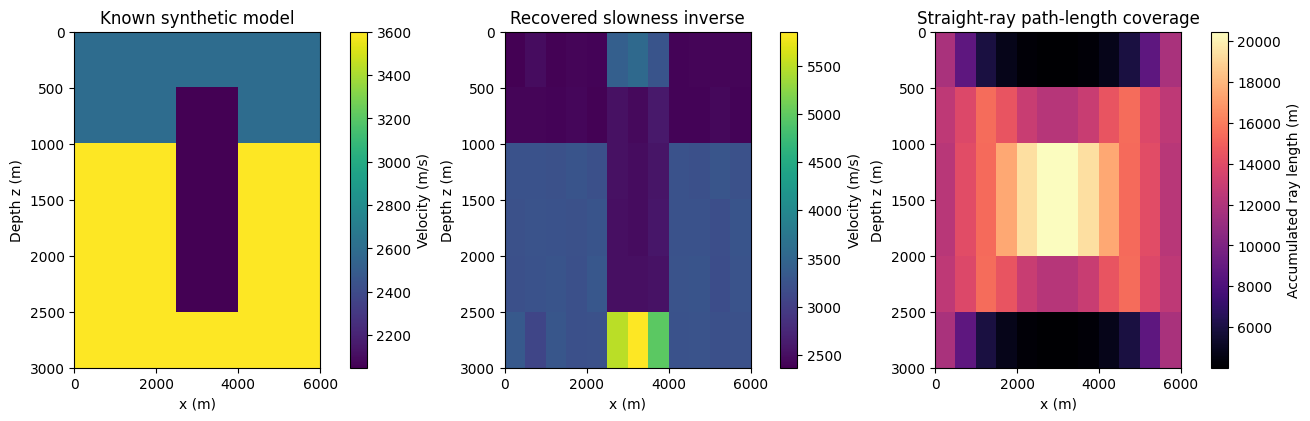

Velocity RMSE against synthetic truth: 534.2767919227546 m/s
Held-out arrivals did not select lambda or model.


In [2]:
# Reproducible notebook experiment cell.
coverage=np.asarray(A.T@np.ones(n_rays)).reshape(nz,nx)
fig,axes=plt.subplots(1,3,figsize=(13,4.1),constrained_layout=True)
extent=[0,nx*dx,nz*dz,0]
for ax,model,title in zip(axes[:2],[velocity_true,velocity_est],
                          ['Known synthetic model','Recovered slowness inverse']):
    im=ax.imshow(model,extent=extent,aspect='auto',cmap='viridis')
    ax.set(title=title,xlabel='x (m)',ylabel='Depth z (m)')
    fig.colorbar(im,ax=ax,label='Velocity (m/s)')
im=axes[2].imshow(coverage,extent=extent,aspect='auto',cmap='magma')
axes[2].set(title='Straight-ray path-length coverage',xlabel='x (m)',ylabel='Depth z (m)')
fig.colorbar(im,ax=axes[2],label='Accumulated ray length (m)')
plt.show()
print('Velocity RMSE against synthetic truth:',float(np.sqrt(np.mean((velocity_est-velocity_true)**2))),'m/s')
print('Held-out arrivals did not select lambda or model.')


## Results

Read training and held-out RMSE/WRMS from the table, and model velocity RMSE from the plot. Read the computed WRMS against the unit-noise target. A value above one means the held-out residual exceeds the assumed pick-noise scale, even if the baseline improves. Do not retune against held-out arrivals.

## Summary
Record both held-out scores, the whole-source split, the smoothness prior, and one limitation of straight-ray coverage.

## References
- [pyGIMLi Koenigsee first-arrival example](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/)
- [pyGIMLi inversion framework](https://www.pygimli.org/user-guide/inversion/)
- Product M09 parser, QC and inverse: data-pipeline/traveltime.py
- Synthetic experiment is generated in memory, not field data.